# PetFinder.my Adoption Prediction

## P1: Initial Data Exploration

**Student:** Min Yang  
**Course:** MSBA 265  
**Professor** Shyla Solis  
**Dataset:** PetFinder.my Adoption Prediction  
**Source:** Kaggle Competition  

### Project Question

Can structured pet profile information available at listing time be used to predict adoption speed and identify profiles that may need additional support?

### Scope

This initial analysis focuses on structured tabular data. Text, image, sentiment, and metadata features are not included in the P1 baseline.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Notebook setup completed successfully.")

Notebook setup completed successfully.


In [2]:
# The notebook is stored in the notebooks folder,
# so "../data/raw" points to the raw data folder.
DATA_DIR = Path("../data/raw")

required_files = [
    "train.csv",
    "breed_labels.csv",
    "color_labels.csv",
    "state_labels.csv",
]

for file_name in required_files:
    file_path = DATA_DIR / file_name
    print(f"{file_name}: {file_path.exists()}")

train.csv: True
breed_labels.csv: True
color_labels.csv: True
state_labels.csv: True


In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
breed_labels = pd.read_csv(DATA_DIR / "breed_labels.csv")
color_labels = pd.read_csv(DATA_DIR / "color_labels.csv")
state_labels = pd.read_csv(DATA_DIR / "state_labels.csv")

print("All CSV files loaded successfully.")
print(f"Training data shape: {train.shape}")

All CSV files loaded successfully.
Training data shape: (14993, 24)


In [4]:
train.head()

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,Vaccinated,Dewormed,Sterilized,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,1,2,2,2,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,2,3,3,3,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,2,1,1,2,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,1,1,1,2,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,1,2,2,2,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


## 1. Initial Data Profile

This section checks the dataset size, column names, data types, missing values, duplicates, and target classes before data cleaning or modeling.

In [5]:
print(f"Number of rows: {train.shape[0]:,}")
print(f"Number of columns: {train.shape[1]}")

print("\nColumn names:")
for number, column in enumerate(train.columns, start=1):
    print(f"{number:02d}. {column}")

Number of rows: 14,993
Number of columns: 24

Column names:
01. Type
02. Name
03. Age
04. Breed1
05. Breed2
06. Gender
07. Color1
08. Color2
09. Color3
10. MaturitySize
11. FurLength
12. Vaccinated
13. Dewormed
14. Sterilized
15. Health
16. Quantity
17. Fee
18. State
19. RescuerID
20. VideoAmt
21. Description
22. PetID
23. PhotoAmt
24. AdoptionSpeed


In [6]:
column_profile = pd.DataFrame({
    "Data Type": train.dtypes.astype(str),
    "Non-Null Count": train.notna().sum(),
    "Missing Count": train.isna().sum(),
    "Unique Values": train.nunique(dropna=False),
})

column_profile


,Data Type,Non-Null Count,Missing Count,Unique Values
Type,int64,14993,0,2
Name,str,13728,1265,9060
Age,int64,14993,0,106
Breed1,int64,14993,0,176
Breed2,int64,14993,0,135
Gender,int64,14993,0,3
Color1,int64,14993,0,7
Color2,int64,14993,0,7
Color3,int64,14993,0,6
MaturitySize,int64,14993,0,4


In [7]:
missing_summary = (
    train.isna()
    .sum()
    .to_frame(name="Missing Count")
)

missing_summary["Missing Percentage"] = (
    missing_summary["Missing Count"] / len(train) * 100
).round(2)

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

if missing_summary.empty:
    print("No standard missing values were found.")
else:
    display(missing_summary)

,Missing Count,Missing Percentage
Name,1265,8.44
Description,13,0.09


In [8]:
duplicate_rows = train.duplicated().sum()
duplicate_pet_ids = train["PetID"].duplicated().sum()

print(f"Fully duplicated rows: {duplicate_rows:,}")
print(f"Duplicated PetID values: {duplicate_pet_ids:,}")
print(f"Unique PetID values: {train['PetID'].nunique():,}")

Fully duplicated rows: 0
Duplicated PetID values: 0
Unique PetID values: 14,993


In [9]:
target_values = sorted(train["AdoptionSpeed"].unique())

print("AdoptionSpeed values:", target_values)
print("Number of target classes:", train["AdoptionSpeed"].nunique())

AdoptionSpeed values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Number of target classes: 5


In [10]:
target_distribution = (
    train["AdoptionSpeed"]
    .value_counts()
    .sort_index()
    .rename_axis("AdoptionSpeed")
    .reset_index(name="Count")
)

target_distribution["Percentage"] = (
    target_distribution["Count"] / len(train) * 100
).round(2)

target_distribution

,AdoptionSpeed,Count,Percentage
0,0,410,2.73
1,1,3090,20.61
2,2,4037,26.93
3,3,3259,21.74
4,4,4197,27.99


### Initial Data Profile Interpretation

The training dataset contains 14,993 pet adoption listings and 24 columns. Each row has a unique PetID, and no fully duplicated rows were found. This suggests that each row represents a separate adoption listing.

Two columns contain standard missing values. The Name column has 1,265 missing values, which represents 8.44% of the dataset. The Description column has only 13 missing values, or 0.09%. These missing values will be reviewed before modeling. However, Name and Description are not planned as direct features in the first tabular baseline.

AdoptionSpeed contains five classes from 0 to 4. The target distribution is not balanced. Class 0 contains only 410 listings, while Class 4 contains 4,197 listings. Because of this imbalance, accuracy alone may not provide a complete measure of model performance. Macro-F1, class-level recall, and a confusion matrix will also be used.

## 2. Target Distribution

The following chart shows the number and percentage of listings in each AdoptionSpeed class.

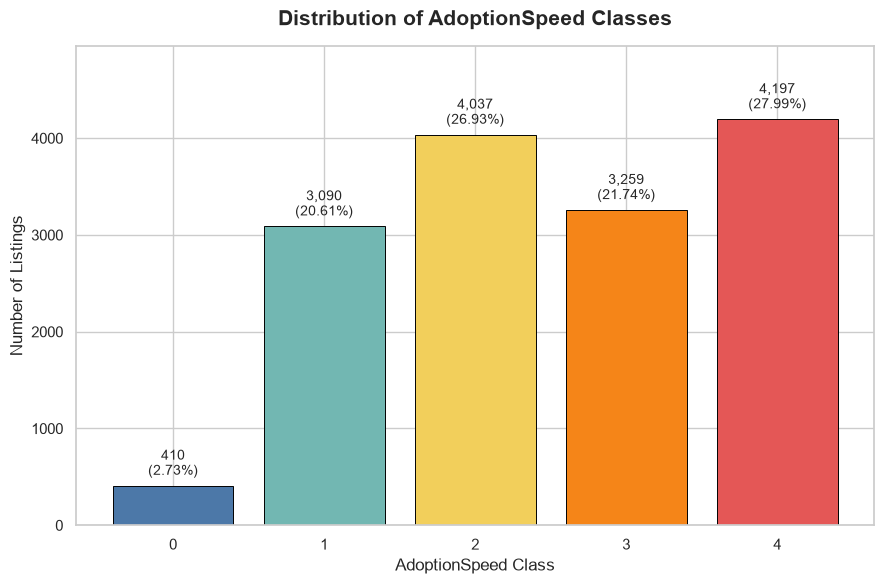

Figure saved to: C:\Users\Min\Documents\python learning\msba265\my_repo\petfinder-adoption-project\figures\adoption_speed_distribution.png


In [11]:
# Create the output folder if it does not already exist.
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Create the target distribution chart.
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    target_distribution["AdoptionSpeed"].astype(str),
    target_distribution["Count"],
    color=["#4C78A8", "#72B7B2", "#F2CF5B", "#F58518", "#E45756"],
    edgecolor="black",
    linewidth=0.7,
)

# Add the count and percentage above each bar.
for bar, count, percentage in zip(
    bars,
    target_distribution["Count"],
    target_distribution["Percentage"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 70,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_title(
    "Distribution of AdoptionSpeed Classes",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("AdoptionSpeed Class")
ax.set_ylabel("Number of Listings")
ax.set_ylim(0, target_distribution["Count"].max() * 1.18)

plt.tight_layout()

# Save the figure for the P1 report.
figure_path = FIGURE_DIR / "adoption_speed_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {figure_path.resolve()}")

### Interpretation

AdoptionSpeed 4 is the largest class, with 4,197 listings or 27.99% of the dataset. AdoptionSpeed 2 is the second largest class, with 4,037 listings or 26.93%. In contrast, AdoptionSpeed 0 contains only 410 listings, or 2.73%.

This distribution shows a clear class imbalance, especially for AdoptionSpeed 0. A model could achieve a reasonable overall accuracy while still performing poorly on the smaller class. Therefore, the data will be split using stratification, and model performance will be evaluated with more than one metric.

## 3. Feature-Level Exploration

### 3.1 Pet Type and AdoptionSpeed

The Type variable uses numeric codes. Type 1 represents dogs, and Type 2 represents cats. This analysis compares the AdoptionSpeed distribution between the two groups.

In [12]:
# Convert numeric type codes into readable labels.
type_labels = {
    1: "Dog",
    2: "Cat",
}

train_eda = train.copy()
train_eda["TypeLabel"] = train_eda["Type"].map(type_labels)

# Check whether every Type value was mapped successfully.
print("Original Type values:", sorted(train["Type"].unique()))
print("Missing TypeLabel values:", train_eda["TypeLabel"].isna().sum())

train_eda[["Type", "TypeLabel"]].drop_duplicates().sort_values("Type")

Original Type values: [np.int64(1), np.int64(2)]
Missing TypeLabel values: 0


,Type,TypeLabel
2,1,Dog
0,2,Cat


In [13]:
type_summary = (
    train_eda["TypeLabel"]
    .value_counts()
    .rename_axis("Pet Type")
    .reset_index(name="Count")
)

type_summary["Percentage"] = (
    type_summary["Count"] / len(train_eda) * 100
).round(2)

type_summary

,Pet Type,Count,Percentage
0,Dog,8132,54.24
1,Cat,6861,45.76


In [14]:
type_adoption_counts = pd.crosstab(
    train_eda["TypeLabel"],
    train_eda["AdoptionSpeed"],
)

type_adoption_percent = (
    pd.crosstab(
        train_eda["TypeLabel"],
        train_eda["AdoptionSpeed"],
        normalize="index",
    ) * 100
).round(2)

print("Counts by pet type:")
display(type_adoption_counts)

print("Percentages within each pet type:")
display(type_adoption_percent)

Counts by pet type:


AdoptionSpeed,0,1,2,3,4
TypeLabel,,,,,
Cat,240,1655,1873,1310,1783
Dog,170,1435,2164,1949,2414


Percentages within each pet type:


AdoptionSpeed,0,1,2,3,4
TypeLabel,,,,,
Cat,3.50,24.12,27.30,19.09,25.99
Dog,2.09,17.65,26.61,23.97,29.69


In [15]:
type_speed_summary = (
    train_eda.groupby("TypeLabel")["AdoptionSpeed"]
    .agg(["count", "mean", "median"])
    .round(2)
)

type_speed_summary

,count,mean,median
TypeLabel,,,
Cat,6861,2.40,2.0
Dog,8132,2.62,3.0


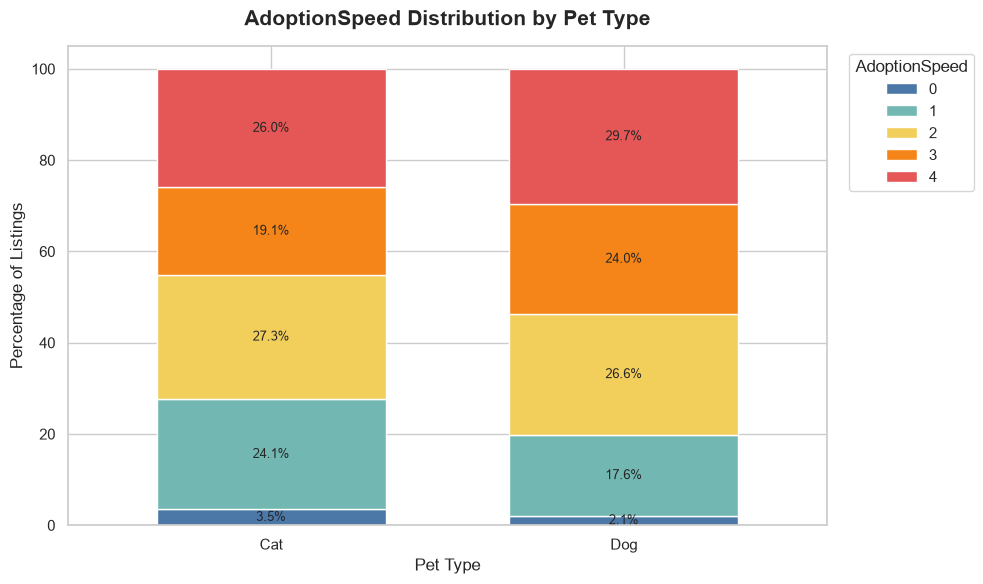

Figure saved to: C:\Users\Min\Documents\python learning\msba265\my_repo\petfinder-adoption-project\figures\adoption_speed_by_pet_type.png


In [16]:
# Create a 100% stacked bar chart.
fig, ax = plt.subplots(figsize=(10, 6))

type_adoption_percent.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#4C78A8", "#72B7B2", "#F2CF5B", "#F58518", "#E45756"],
    edgecolor="white",
    width=0.65,
)

# Add percentage labels inside each section.
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 2 else ""
        for value in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
    )

ax.set_title(
    "AdoptionSpeed Distribution by Pet Type",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Pet Type")
ax.set_ylabel("Percentage of Listings")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(
    title="AdoptionSpeed",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()

type_figure_path = FIGURE_DIR / "adoption_speed_by_pet_type.png"
plt.savefig(type_figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {type_figure_path.resolve()}")

### Interpretation

Dogs represent 54.24% of the listings, while cats represent 45.76%, so both groups have enough observations for a basic comparison.

The distribution shows that cats are more common in the faster adoption classes. AdoptionSpeed 0 and 1 together account for 27.62% of cat listings, compared with 19.74% of dog listings. In contrast, AdoptionSpeed 3 and 4 together account for 53.66% of dog listings and 45.08% of cat listings.

The median AdoptionSpeed is 3 for dogs and 2 for cats. This suggests that dogs in this dataset tend to appear in slower adoption categories more often than cats. However, this result shows an association only. Other factors, such as age, breed, health, location, and profile quality, may also contribute to the difference.

### 3.2 Pet Age and AdoptionSpeed

The Age variable represents the pet's age in months. Before comparing age with AdoptionSpeed, the distribution and unusually high or low values are reviewed.

In [17]:
age_summary = train_eda["Age"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

age_summary

count    14993.000000
mean        10.452078
std         18.155790
min          0.000000
1%           0.000000
5%           1.000000
25%          2.000000
50%          3.000000
75%         12.000000
90%         28.000000
95%         48.000000
99%         84.000000
max        255.000000
Name: Age, dtype: float64

In [18]:
age_checks = pd.Series({
    "Age equal to 0 months": (train_eda["Age"] == 0).sum(),
    "Age over 120 months": (train_eda["Age"] > 120).sum(),
    "Age over 180 months": (train_eda["Age"] > 180).sum(),
    "Age over 240 months": (train_eda["Age"] > 240).sum(),
})

age_checks

Age equal to 0 months    179
Age over 120 months       26
Age over 180 months        6
Age over 240 months        2
dtype: int64

In [19]:
most_common_ages = (
    train_eda["Age"]
    .value_counts()
    .head(15)
    .rename_axis("Age in Months")
    .reset_index(name="Count")
)

most_common_ages

,Age in Months,Count
0,2,3503
1,1,2304
2,3,1966
3,4,1109
4,12,967
5,24,651
6,5,595
7,6,558
8,36,417
9,8,309


In [20]:
oldest_records = (
    train_eda[
        [
            "PetID",
            "TypeLabel",
            "Age",
            "Breed1",
            "Health",
            "AdoptionSpeed",
        ]
    ]
    .sort_values("Age", ascending=False)
    .head(15)
)

oldest_records

,PetID,TypeLabel,Age,Breed1,Health,AdoptionSpeed
11172,50682d0f1,Dog,255,307,1,4
5160,5971c2462,Dog,255,307,1,4
13398,e01f077a7,Dog,238,307,1,4
12855,36d7fc2c5,Dog,212,307,1,4
11087,e77f9e778,Cat,212,266,1,3
3998,53923463d,Cat,212,266,1,3
8492,1d669183f,Dog,180,307,1,4
14637,bd006f963,Cat,180,265,1,3
9267,e5ffc0a9d,Dog,168,69,1,3
7512,739cd2d34,Dog,156,307,1,2


In [21]:
old_age_distribution = (
    train_eda.loc[train_eda["Age"] >= 120, "Age"]
    .value_counts()
    .sort_index()
    .rename_axis("Age in Months")
    .reset_index(name="Count")
)

old_age_distribution.tail(20)

,Age in Months,Count
0,120,33
1,122,1
2,123,1
3,132,8
4,135,1
5,144,4
6,147,1
7,156,1
8,168,1
9,180,2


#### Age Group Preparation

The Age distribution is strongly right-skewed. The median age is 3 months, while the maximum is 255 months. Most listings represent young pets, but a small number of senior pets are also included.

The records are grouped into broader age ranges for easier comparison. No records are removed. Age values of 84 months or more are combined into one senior group to reduce the influence of small and unusual age values.

In [22]:
# Create broader age groups without deleting any observations.
age_bins = [-1, 5, 11, 35, 83, np.inf]

age_labels = [
    "0–5 months",
    "6–11 months",
    "12–35 months",
    "36–83 months",
    "84+ months",
]

train_eda["AgeGroup"] = pd.cut(
    train_eda["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True,
    ordered=True,
)

print("Missing AgeGroup values:", train_eda["AgeGroup"].isna().sum())

Missing AgeGroup values: 0


In [23]:
age_group_summary = (
    train_eda["AgeGroup"]
    .value_counts(sort=False)
    .rename_axis("Age Group")
    .reset_index(name="Count")
)

age_group_summary["Percentage"] = (
    age_group_summary["Count"] / len(train_eda) * 100
).round(2)

age_group_summary

,Age Group,Count,Percentage
0,0–5 months,9656,64.40
1,6–11 months,1588,10.59
2,12–35 months,2374,15.83
3,36–83 months,1132,7.55
4,84+ months,243,1.62


In [24]:
age_adoption_counts = pd.crosstab(
    train_eda["AgeGroup"],
    train_eda["AdoptionSpeed"],
    dropna=False,
)

age_adoption_percent = (
    pd.crosstab(
        train_eda["AgeGroup"],
        train_eda["AdoptionSpeed"],
        normalize="index",
        dropna=False,
    ) * 100
).round(2)

print("Counts by age group:")
display(age_adoption_counts)

print("Percentages within each age group:")
display(age_adoption_percent)

Counts by age group:


AdoptionSpeed,0,1,2,3,4
AgeGroup,,,,,
0–5 months,254,2277,2926,2186,2013
6–11 months,43,217,349,330,649
12–35 months,81,355,447,465,1026
36–83 months,26,207,258,217,424
84+ months,6,34,57,61,85


Percentages within each age group:


AdoptionSpeed,0,1,2,3,4
AgeGroup,,,,,
0–5 months,2.63,23.58,30.30,22.64,20.85
6–11 months,2.71,13.66,21.98,20.78,40.87
12–35 months,3.41,14.95,18.83,19.59,43.22
36–83 months,2.30,18.29,22.79,19.17,37.46
84+ months,2.47,13.99,23.46,25.10,34.98


In [25]:
age_speed_summary = (
    train_eda.groupby(
        "AgeGroup",
        observed=True,
    )["AdoptionSpeed"]
    .agg(["count", "mean", "median"])
    .round(2)
)

age_speed_summary

,count,mean,median
AgeGroup,,,
0–5 months,9656,2.35,2.0
6–11 months,1588,2.83,3.0
12–35 months,2374,2.84,3.0
36–83 months,1132,2.71,3.0
84+ months,243,2.76,3.0


#### Age Data Limitation

The Age variable ranges from 0 to 255 months. A small number of records contain unusually high ages, including two listings at 255 months. These values may represent very old pets, estimated ages, or data-entry issues. There is not enough evidence to identify the exact cause, so the records are retained and grouped into the 84+ months category. This limitation should be considered when interpreting the results.

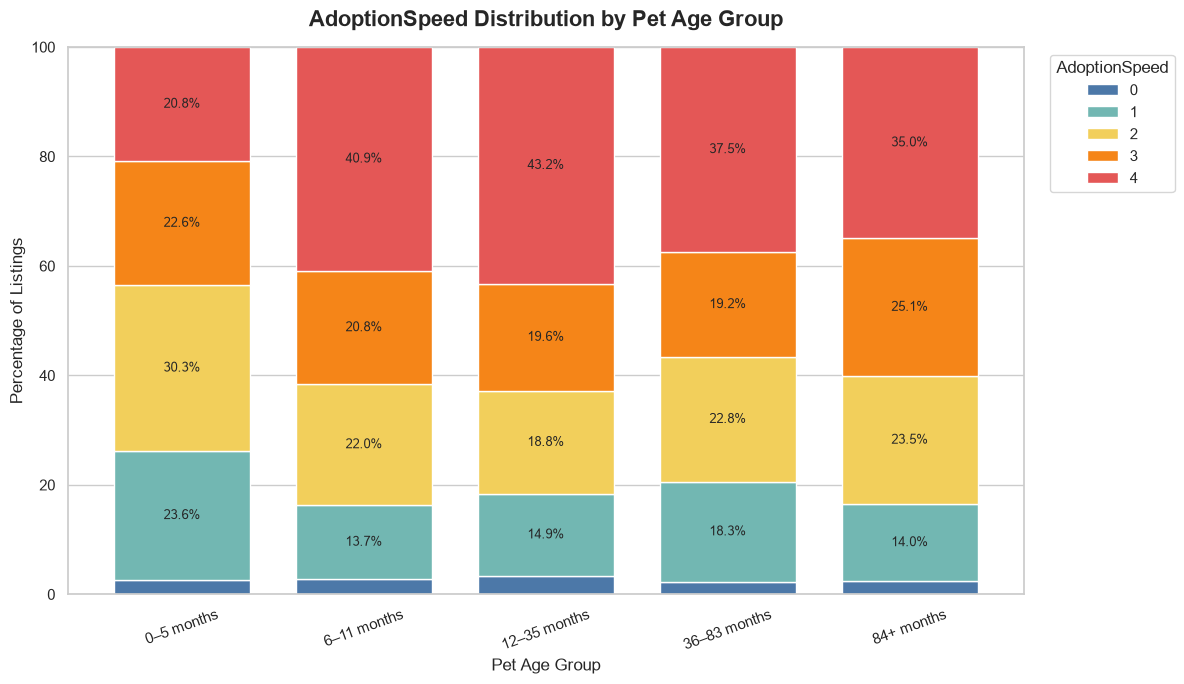

Figure saved to: C:\Users\Min\Documents\python learning\msba265\my_repo\petfinder-adoption-project\figures\adoption_speed_by_age_group.png


In [26]:
# Create a 100% stacked bar chart for age groups.

fig, ax = plt.subplots(figsize=(12, 7))

age_adoption_percent.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#4C78A8", "#72B7B2", "#F2CF5B", "#F58518", "#E45756"],
    edgecolor="white",
    width=0.75,
)

# Add percentage labels to segments that are large enough.
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 4 else ""
        for value in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
    )

ax.set_title(
    "AdoptionSpeed Distribution by Pet Age Group",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Pet Age Group", fontsize=12)
ax.set_ylabel("Percentage of Listings", fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=20)

ax.legend(
    title="AdoptionSpeed",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()

age_figure_path = FIGURE_DIR / "adoption_speed_by_age_group.png"
plt.savefig(age_figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {age_figure_path.resolve()}")

### Interpretation

Most pets in the dataset are young. The 0–5 months group contains 9,656 listings, or 64.40% of the dataset. In comparison, the 84+ months group contains only 243 listings, or 1.62%.

The youngest pets generally appear in faster adoption classes. The mean AdoptionSpeed is 2.35 for pets aged 0–5 months, while the mean values for the other age groups range from 2.71 to 2.84. AdoptionSpeed 4 represents 20.85% of the 0–5 months group, compared with 43.22% of the 12–35 months group.

However, the relationship is not completely linear. The mean AdoptionSpeed does not continue to increase in every older age group. This suggests that age may be related to adoption speed, but other factors may also affect the result.

The 84+ months group is small and includes some unusually high age values. Therefore, results for this group should be interpreted carefully. This analysis shows an association and does not prove that age causes slower adoption.

### 3.3 Adoption Fee and AdoptionSpeed

The Fee variable represents the adoption fee listed in Malaysian ringgit. Before comparing Fee with AdoptionSpeed, the distribution, free listings, and unusually high values are reviewed.

In [27]:
fee_summary = train_eda["Fee"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

fee_summary

count    14993.000000
mean        21.259988
std         78.414548
min          0.000000
1%           0.000000
5%           0.000000
25%          0.000000
50%          0.000000
75%          0.000000
90%         50.000000
95%        150.000000
99%        350.000000
max       3000.000000
Name: Fee, dtype: float64

In [28]:
fee_checks = pd.Series({
    "Fee equal to 0": (train_eda["Fee"] == 0).sum(),
    "Fee greater than 100": (train_eda["Fee"] > 100).sum(),
    "Fee greater than 200": (train_eda["Fee"] > 200).sum(),
    "Fee greater than 500": (train_eda["Fee"] > 500).sum(),
})

fee_checks

Fee equal to 0          12663
Fee greater than 100      860
Fee greater than 200      423
Fee greater than 500       44
dtype: int64

In [29]:
most_common_fees = (
    train_eda["Fee"]
    .value_counts()
    .head(15)
    .rename_axis("Fee")
    .reset_index(name="Count")
)

most_common_fees

,Fee,Count
0,0,12663
1,50,468
2,100,408
3,200,219
4,150,162
5,20,136
6,300,120
7,30,103
8,250,92
9,1,82


#### Fee Group Preparation

The Fee distribution is strongly right-skewed and contains many zero values. A total of 12,663 listings, or 84.46% of the dataset, have no adoption fee. The median is RM 0, while the maximum is RM 3,000.

The records are grouped into broader fee ranges for comparison. Free listings are kept as a separate group because they represent most of the dataset. No observations are removed.

In [30]:
# Create fee groups without deleting any observations.

fee_bins = [-1, 0, 50, 100, 200, np.inf]

fee_labels = [
    "Free",
    "RM 1–50",
    "RM 51–100",
    "RM 101–200",
    "RM 201+",
]

train_eda["FeeGroup"] = pd.cut(
    train_eda["Fee"],
    bins=fee_bins,
    labels=fee_labels,
    include_lowest=True,
    ordered=True,
)

print("Missing FeeGroup values:", train_eda["FeeGroup"].isna().sum())

Missing FeeGroup values: 0


In [31]:
fee_group_summary = (
    train_eda["FeeGroup"]
    .value_counts(sort=False)
    .rename_axis("Fee Group")
    .reset_index(name="Count")
)

fee_group_summary["Percentage"] = (
    fee_group_summary["Count"] / len(train_eda) * 100
).round(2)

fee_group_summary

,Fee Group,Count,Percentage
0,Free,12663,84.46
1,RM 1–50,954,6.36
2,RM 51–100,516,3.44
3,RM 101–200,437,2.91
4,RM 201+,423,2.82


In [32]:
fee_adoption_counts = pd.crosstab(
    train_eda["FeeGroup"],
    train_eda["AdoptionSpeed"],
    dropna=False,
)

fee_adoption_percent = (
    pd.crosstab(
        train_eda["FeeGroup"],
        train_eda["AdoptionSpeed"],
        normalize="index",
        dropna=False,
    ) * 100
).round(2)

print("Counts by fee group:")
display(fee_adoption_counts)

print("Percentages within each fee group:")
display(fee_adoption_percent)

Counts by fee group:


AdoptionSpeed,0,1,2,3,4
FeeGroup,,,,,
Free,357,2611,3430,2789,3476
RM 1–50,18,208,261,191,276
RM 51–100,11,88,115,101,201
RM 101–200,11,91,112,90,133
RM 201+,13,92,119,88,111


Percentages within each fee group:


AdoptionSpeed,0,1,2,3,4
FeeGroup,,,,,
Free,2.82,20.62,27.09,22.02,27.45
RM 1–50,1.89,21.80,27.36,20.02,28.93
RM 51–100,2.13,17.05,22.29,19.57,38.95
RM 101–200,2.52,20.82,25.63,20.59,30.43
RM 201+,3.07,21.75,28.13,20.80,26.24


In [33]:
fee_speed_summary = (
    train_eda.groupby(
        "FeeGroup",
        observed=True,
    )["AdoptionSpeed"]
    .agg(["count", "mean", "median"])
    .round(2)
)

fee_speed_summary

,count,mean,median
FeeGroup,,,
Free,12663,2.51,2.0
RM 1–50,954,2.52,2.0
RM 51–100,516,2.76,3.0
RM 101–200,437,2.56,3.0
RM 201+,423,2.45,2.0


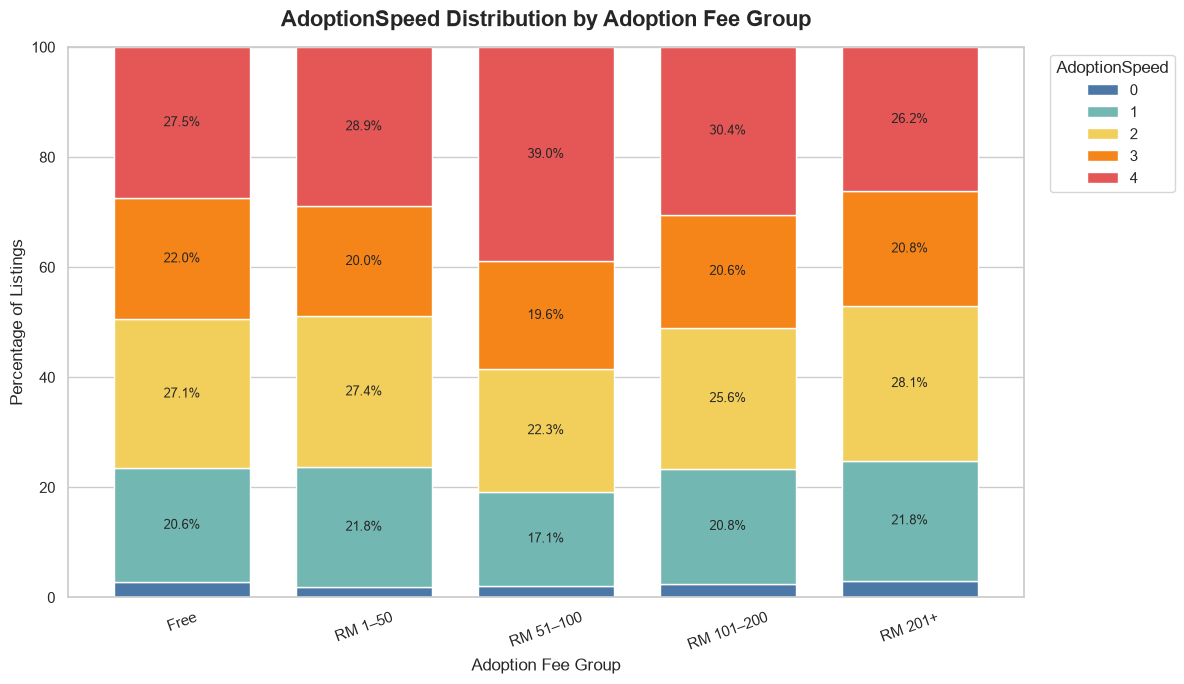

Figure saved to: C:\Users\Min\Documents\python learning\msba265\my_repo\petfinder-adoption-project\figures\adoption_speed_by_fee_group.png


In [34]:
# Create a 100% stacked bar chart for fee groups.

fig, ax = plt.subplots(figsize=(12, 7))

fee_adoption_percent.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#4C78A8", "#72B7B2", "#F2CF5B", "#F58518", "#E45756"],
    edgecolor="white",
    width=0.75,
)

# Add labels only when the segment is large enough.
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 4 else ""
        for value in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
    )

ax.set_title(
    "AdoptionSpeed Distribution by Adoption Fee Group",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Adoption Fee Group", fontsize=12)
ax.set_ylabel("Percentage of Listings", fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=20)

ax.legend(
    title="AdoptionSpeed",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()

fee_figure_path = FIGURE_DIR / "adoption_speed_by_fee_group.png"
plt.savefig(fee_figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {fee_figure_path.resolve()}")

#### Interpretation

Most listings do not charge an adoption fee. The Free group contains 12,663 listings, or 84.46% of the dataset. The other fee groups are much smaller, with each group representing less than 7% of the data.

The results do not show a simple relationship between adoption fee and AdoptionSpeed. The RM 51–100 group has the highest mean AdoptionSpeed at 2.76, and 38.95% of its listings are in AdoptionSpeed 4. However, the RM 201+ group has a lower mean of 2.45, and 26.24% of its listings are in AdoptionSpeed 4.

This means that AdoptionSpeed does not continuously increase as the adoption fee becomes higher. Fee may provide useful information for prediction, but its relationship with adoption speed is not linear.

The fee groups are also very different in size. Since the Free group represents most of the dataset, comparisons with the smaller paid-fee groups should be interpreted carefully. These results show an association and do not prove that adoption fees cause faster or slower adoption.

### 3.4 Number of Photos and AdoptionSpeed

The PhotoAmt variable represents the number of photos included in each pet listing. Photos may help potential adopters understand the pet's appearance and condition. This section first reviews the distribution and checks listings with few or unusually many photos.

In [35]:
photo_summary = train_eda["PhotoAmt"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

photo_summary

count    14993.000000
mean         3.889215
std          3.487810
min          0.000000
1%           0.000000
5%           1.000000
25%          2.000000
50%          3.000000
75%          5.000000
90%          7.000000
95%         10.000000
99%         19.000000
max         30.000000
Name: PhotoAmt, dtype: float64

In [36]:
photo_checks = pd.Series({
    "No photos": (train_eda["PhotoAmt"] == 0).sum(),
    "Exactly 1 photo": (train_eda["PhotoAmt"] == 1).sum(),
    "At least 5 photos": (train_eda["PhotoAmt"] >= 5).sum(),
    "At least 10 photos": (train_eda["PhotoAmt"] >= 10).sum(),
    "More than 20 photos": (train_eda["PhotoAmt"] > 20).sum(),
})

photo_checks

No photos               341
Exactly 1 photo        3075
At least 5 photos      4667
At least 10 photos      922
More than 20 photos     108
dtype: int64

In [37]:
photo_distribution = (
    train_eda["PhotoAmt"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Photos")
    .reset_index(name="Count")
)

photo_distribution["Percentage"] = (
    photo_distribution["Count"] / len(train_eda) * 100
).round(2)

photo_distribution

,Number of Photos,Count,Percentage
0,0.0,341,2.27
1,1.0,3075,20.51
2,2.0,2518,16.79
3,3.0,2511,16.75
4,4.0,1881,12.55
5,5.0,2147,14.32
6,6.0,621,4.14
7,7.0,432,2.88
8,8.0,314,2.09
9,9.0,231,1.54


#### Photo Group Preparation

The median listing contains 3 photos, while the maximum is 30 photos. A total of 341 listings, or 2.27% of the dataset, have no photos. Listings with very high photo counts are uncommon, but the values are still possible.

The records are grouped into broader photo ranges for easier comparison. Listings with no photos and listings with only one photo are kept as separate groups because they may represent less complete pet profiles. No observations are removed.

In [38]:
# Create photo groups without deleting any observations.

photo_bins = [-1, 0, 1, 3, 5, np.inf]

photo_labels = [
    "No photos",
    "1 photo",
    "2–3 photos",
    "4–5 photos",
    "6+ photos",
]

train_eda["PhotoGroup"] = pd.cut(
    train_eda["PhotoAmt"],
    bins=photo_bins,
    labels=photo_labels,
    include_lowest=True,
    ordered=True,
)

print("Missing PhotoGroup values:", train_eda["PhotoGroup"].isna().sum())

Missing PhotoGroup values: 0


In [39]:
photo_group_summary = (
    train_eda["PhotoGroup"]
    .value_counts(sort=False)
    .rename_axis("Photo Group")
    .reset_index(name="Count")
)

photo_group_summary["Percentage"] = (
    photo_group_summary["Count"] / len(train_eda) * 100
).round(2)

photo_group_summary

,Photo Group,Count,Percentage
0,No photos,341,2.27
1,1 photo,3075,20.51
2,2–3 photos,5029,33.54
3,4–5 photos,4028,26.87
4,6+ photos,2520,16.81


In [40]:
photo_adoption_counts = pd.crosstab(
    train_eda["PhotoGroup"],
    train_eda["AdoptionSpeed"],
    dropna=False,
)

photo_adoption_percent = (
    pd.crosstab(
        train_eda["PhotoGroup"],
        train_eda["AdoptionSpeed"],
        normalize="index",
        dropna=False,
    ) * 100
).round(2)

print("Counts by photo group:")
display(photo_adoption_counts)

print("Percentages within each photo group:")
display(photo_adoption_percent)

Counts by photo group:


AdoptionSpeed,0,1,2,3,4
PhotoGroup,,,,,
No photos,24,34,36,34,213
1 photo,75,615,783,592,1010
2–3 photos,158,1084,1331,983,1473
4–5 photos,110,919,1129,835,1035
6+ photos,43,438,758,815,466


Percentages within each photo group:


AdoptionSpeed,0,1,2,3,4
PhotoGroup,,,,,
No photos,7.04,9.97,10.56,9.97,62.46
1 photo,2.44,20.00,25.46,19.25,32.85
2–3 photos,3.14,21.55,26.47,19.55,29.29
4–5 photos,2.73,22.82,28.03,20.73,25.70
6+ photos,1.71,17.38,30.08,32.34,18.49


In [41]:
photo_speed_summary = (
    train_eda.groupby(
        "PhotoGroup",
        observed=True,
    )["AdoptionSpeed"]
    .agg(["count", "mean", "median"])
    .round(2)
)

photo_speed_summary

,count,mean,median
PhotoGroup,,,
No photos,341,3.11,4.0
1 photo,3075,2.60,3.0
2–3 photos,5029,2.50,2.0
4–5 photos,4028,2.44,2.0
6+ photos,2520,2.49,3.0


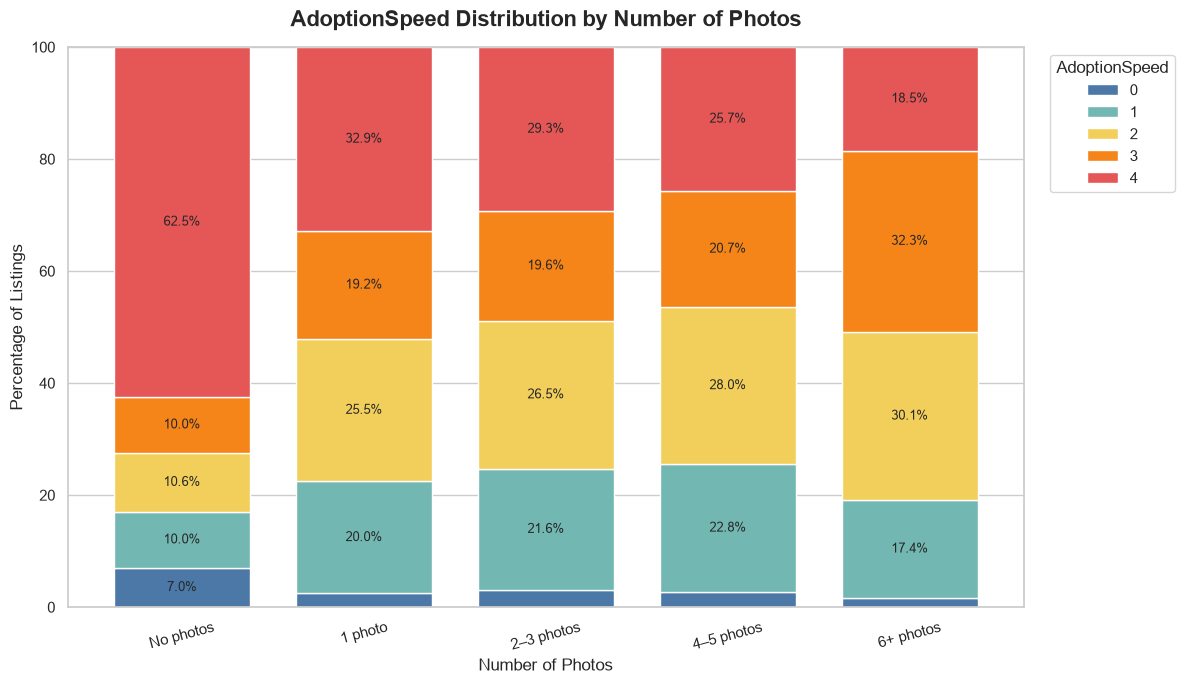

Figure saved to: C:\Users\Min\Documents\python learning\msba265\my_repo\petfinder-adoption-project\figures\adoption_speed_by_photo_group.png


In [42]:
# Create a 100% stacked bar chart for photo groups.

fig, ax = plt.subplots(figsize=(12, 7))

photo_adoption_percent.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#4C78A8", "#72B7B2", "#F2CF5B", "#F58518", "#E45756"],
    edgecolor="white",
    width=0.75,
)

# Add percentage labels to segments that are large enough.
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 4 else ""
        for value in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
    )

ax.set_title(
    "AdoptionSpeed Distribution by Number of Photos",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Number of Photos", fontsize=12)
ax.set_ylabel("Percentage of Listings", fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=15)

ax.legend(
    title="AdoptionSpeed",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()

photo_figure_path = FIGURE_DIR / "adoption_speed_by_photo_group.png"
plt.savefig(photo_figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {photo_figure_path.resolve()}")

#### Interpretation

The number of photos shows a clear relationship with AdoptionSpeed. Listings without photos have the highest mean AdoptionSpeed at 3.11, and their median is 4. In this group, 62.46% of the listings are in AdoptionSpeed 4.

The percentage of AdoptionSpeed 4 becomes lower as the number of photos increases. It decreases from 62.46% for listings without photos to 32.85% for listings with one photo, 29.29% for listings with 2–3 photos, 25.70% for listings with 4–5 photos, and 18.49% for listings with 6 or more photos.

However, the mean AdoptionSpeed does not decrease continuously. It falls from 3.11 for listings without photos to 2.44 for listings with 4–5 photos, but it increases slightly to 2.49 for listings with 6 or more photos. Therefore, more photos do not always lead to a faster adoption class.

The no-photo group contains only 341 listings, so its results should be interpreted carefully. The findings show an association and do not prove that adding photos directly causes faster adoption. Other factors, such as pet age, profile quality, and rescuer activity, may also affect the result.

## 4. Key Findings

The initial exploration produced four main findings:

1. **The target classes are imbalanced.** AdoptionSpeed 4 is the largest class at 27.99%, while AdoptionSpeed 0 represents only 2.73% of the dataset. A future model should not be evaluated by accuracy alone.

2. **Pet type is related to adoption speed.** Cats have a lower mean AdoptionSpeed than dogs (2.40 compared with 2.62). However, pet type alone cannot explain the outcome.

3. **Young pets generally appear in faster adoption classes.** Pets aged 0–5 months have the lowest mean AdoptionSpeed at 2.35. The relationship is not fully linear across the older age groups.

4. **The number of photos is the clearest actionable feature in this analysis.** AdoptionSpeed 4 represents 62.46% of listings without photos, compared with 18.49% of listings with 6 or more photos.

Adoption fee shows some differences between groups, but it does not have a clear increasing or decreasing relationship with AdoptionSpeed.

## 5. Data Limitations

This analysis has several limitations:

- The data shows associations and cannot prove cause and effect.
- The dataset contains only PetFinder.my listings and may not represent pet adoption in other countries or platforms.
- Some groups are much smaller than others, especially AdoptionSpeed 0, pets without photos, and older pets.
- The Age variable contains a small number of unusually high values. These records were retained because there was not enough evidence to identify them as errors.
- Pet profiles may change after they are first published, but the dataset does not show when each feature was updated.
- Text, image, sentiment, and metadata files were not included in the P1 baseline analysis.
- Important outside factors, such as adoption events, social media promotion, or communication between adopters and rescuers, are not available in the structured data.

## 6. Proposed Modeling Plan

The next phase will build an explainable baseline model to predict the five AdoptionSpeed classes.

### Baseline model

A Decision Tree classifier will be used as the first model because its rules can be reviewed and explained. If time allows, a Random Forest model may be added for comparison.

### Initial structured features

The first model may include:

- Type
- Age
- Breed1 and Breed2
- Gender
- MaturitySize
- FurLength
- Vaccinated
- Dewormed
- Sterilized
- Health
- Quantity
- Fee
- State
- VideoAmt
- PhotoAmt

PetID will not be used as a predictor because it is a unique identifier. Name and Description will not be included in the first structured baseline because they require additional text processing.

### Validation plan

The data will be divided into training and validation sets using stratification so that each AdoptionSpeed class keeps a similar proportion. Model performance will be reviewed with more than one metric, including accuracy, macro F1-score, a confusion matrix, and quadratic weighted kappa.

The Decision Tree will be kept reasonably small to reduce overfitting and make the results easier to explain.

## 7. P1 Conclusion

The PetFinder.my dataset is suitable for the semester project. It contains 14,993 training listings and a mix of pet characteristics, health information, location, adoption fee, and profile quality features.

The initial analysis shows that AdoptionSpeed is related to several structured features. Pet type and age show meaningful differences, while adoption fee has a less consistent relationship. The number of photos provides the clearest practical finding because listings without photos are much more common in AdoptionSpeed 4.

These findings support the proposed modeling question and show that the project is feasible. The next phase will prepare the structured features, build an explainable Decision Tree baseline, and evaluate how well the model identifies pets that may need additional adoption support.

In [43]:
# Final P1 notebook checks.

expected_figures = [
    "adoption_speed_distribution.png",
    "adoption_speed_by_pet_type.png",
    "adoption_speed_by_age_group.png",
    "adoption_speed_by_fee_group.png",
    "adoption_speed_by_photo_group.png",
]

figure_check = pd.DataFrame({
    "Figure": expected_figures,
    "Exists": [
        (FIGURE_DIR / figure_name).exists()
        for figure_name in expected_figures
    ],
})

print("Training rows:", len(train_eda))
print("Training columns in EDA copy:", train_eda.shape[1])
print("Missing AgeGroup values:", train_eda["AgeGroup"].isna().sum())
print("Missing FeeGroup values:", train_eda["FeeGroup"].isna().sum())
print("Missing PhotoGroup values:", train_eda["PhotoGroup"].isna().sum())

display(figure_check)

Training rows: 14993
Training columns in EDA copy: 28
Missing AgeGroup values: 0
Missing FeeGroup values: 0
Missing PhotoGroup values: 0


,Figure,Exists
0,adoption_speed_distribution.png,True
1,adoption_speed_by_pet_type.png,True
2,adoption_speed_by_age_group.png,True
3,adoption_speed_by_fee_group.png,True
4,adoption_speed_by_photo_group.png,True
